In [22]:
# Import the required library to upload files in Google Colab
# Run this cell, click "Choose Files", and select "Waste Management and Recycle of Indian Cities"
from google.colab import files
uploaded = files.upload()

Saving Waste_Management_India_20K.csv to Waste_Management_India_20K.csv


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [24]:
# 1. Load the dataset (Make sure the exact filename matches the uploaded file)
df = pd.read_csv("Waste_Management_India_20K.csv")

In [25]:
# 2. Initial Overview
print("Dataset Shape:", df.shape)
display(df.head())
display(df.info())

Dataset Shape: (25203, 42)


,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,...,Latitude,Longitude,Air_Quality_Index,Rainfall_MM,Tourism_Impact_Score,Industrial_Activity_Level,Population_Growth_Rate,Sustainability_Index,Waste_Management_Performance_Level,Sustainability_Category
0,WM000001,Agartala,Tripura,Northeast,Tier-3,2015,1,Winter,172974,2175.5,...,23.8315,91.2868,155,23.0,4.7,1.8,3.08,33.3,Low,Poor
1,WM000002,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,...,27.1767,78.0081,225,16.3,10.0,8.7,1.63,43.0,Low,Average
2,WM000003,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,...,27.1767,78.0081,225,16.3,10.0,8.7,1.63,43.5,Medium,Average
3,WM000004,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,...,23.0225,72.5714,162,8.7,6.6,4.9,1.62,42.6,High,Average
4,WM000005,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,...,23.0225,72.5714,162,8.7,6.6,4.9,1.62,49.7,High,Good


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25203 entries, 0 to 25202
Data columns (total 42 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Record_ID                           25203 non-null  object 
 1   City                                25203 non-null  object 
 2   State                               25203 non-null  object 
 3   Region                              25203 non-null  object 
 4   City_Category                       25203 non-null  object 
 5   Year                                25203 non-null  int64  
 6   Month                               25203 non-null  int64  
 7   Season                              25203 non-null  object 
 8   Population                          25203 non-null  int64  
 9   Population_Density                  25203 non-null  float64
 10  Urbanization_Rate                   25203 non-null  float64
 11  Waste_Type                          25203

None

In [26]:
# 3. Data Cleaning & Derived Features
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

In [27]:
# Create derived columns for deeper analysis
df['Annual_Waste_Generation_Tons'] = df['Daily_Waste_Generation_Tons'] * 365
df['Budget_Per_Ton'] = df['Waste_Management_Budget_INR'] / df['Annual_Waste_Generation_Tons']

print("Pre-processing complete. Ready for analysis.")

Pre-processing complete. Ready for analysis.


In [28]:
# Set up the visualization layout
sns.set_theme(style="whitegrid", palette="muted")
plt.figure(figsize=(20, 25))

<Figure size 2000x2500 with 0 Axes>

<Figure size 2000x2500 with 0 Axes>

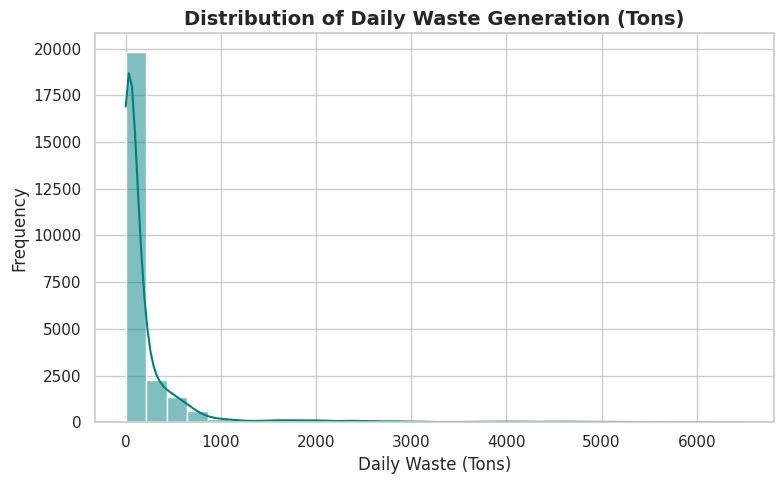

In [31]:
# 1. Distribution of Daily Waste Generation
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.figure(figsize=(8, 5))
sns.histplot(df['Daily_Waste_Generation_Tons'], bins=30, kde=True, color='teal')
plt.title('Distribution of Daily Waste Generation (Tons)', fontsize=14, fontweight='bold')
plt.xlabel('Daily Waste (Tons)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
Chart 1: Distribution of Daily Waste Generation (Histogram)

What it shows: How much daily waste most cities produce.

In simple terms: It groups cities by how many tons of trash they throw out daily. You can easily see what the "normal" amount of daily waste is across the country.

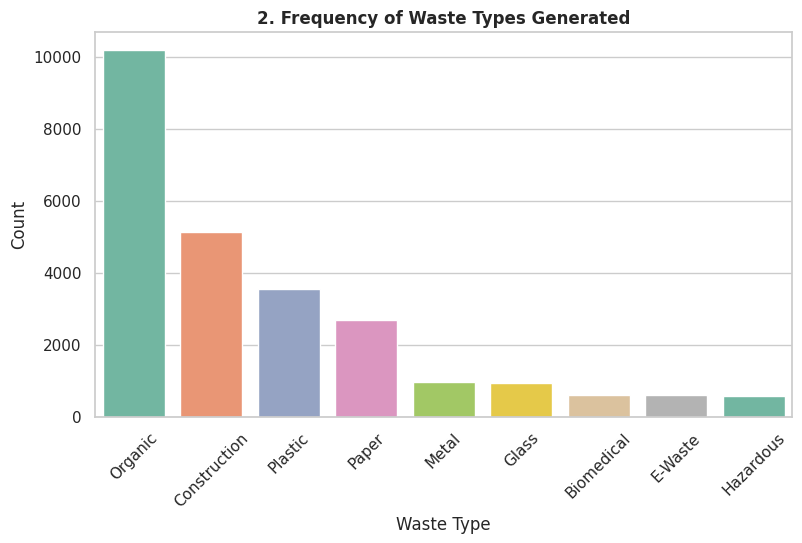

In [38]:
# 2. Frequency of Waste Types
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='Waste_Type', order=df['Waste_Type'].value_counts().index, palette='Set2')
plt.title('2. Frequency of Waste Types Generated', fontsize=12, fontweight='bold')
plt.xlabel('Waste Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

In [ ]:
Chart 2: Frequency of Waste Types Generated (Count Plot)

What it shows: Which type of waste appears the most in our data (like Organic, Plastic, E-waste, etc.).

In simple terms: It's a simple tally counter showing which category of trash is the most common.

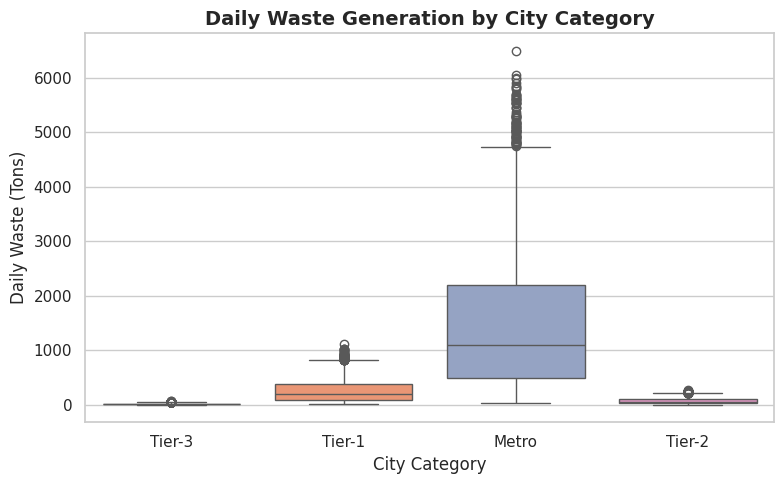

In [32]:
# 3. Daily Waste Generation by City Category
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='City_Category', y='Daily_Waste_Generation_Tons', palette='Set2')
plt.title('Daily Waste Generation by City Category', fontsize=14, fontweight='bold')
plt.xlabel('City Category', fontsize=12)
plt.ylabel('Daily Waste (Tons)', fontsize=12)
plt.tight_layout()
plt.show()



In [ ]:
Chart 3: Daily Waste Generation by City Category (Box Plot)

What it shows: How waste amounts change based on city sizes (from Metros down to Tier-3 towns).

In simple terms: It compares big cities against small towns to prove that larger cities produce way more trash.

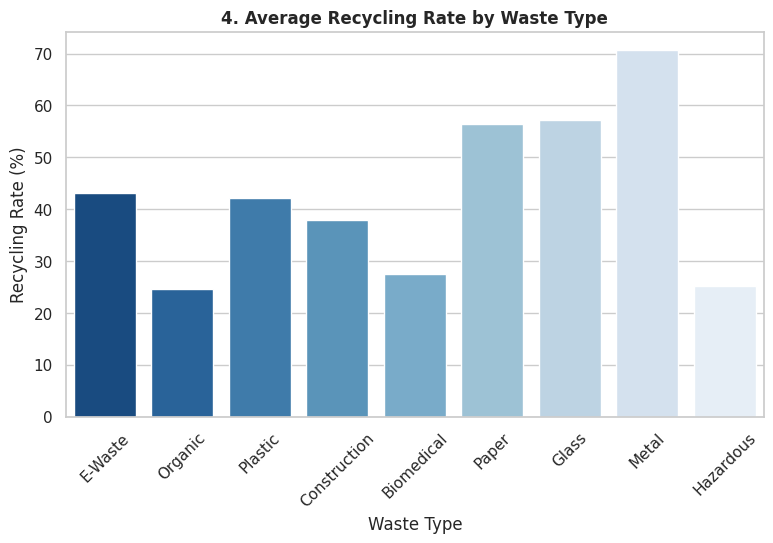

In [39]:
# 4. Average Recycling Rate by Waste Type
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x='Waste_Type', y='Recycling_Rate', errorbar=None, palette='Blues_r')
plt.title('4. Average Recycling Rate by Waste Type', fontsize=12, fontweight='bold')
plt.xlabel('Waste Type')
plt.ylabel('Recycling Rate (%)')
plt.xticks(rotation=45)
plt.show()

In [ ]:
Chart 4: Average Recycling Rate by Waste Type (Bar Plot)

What it shows: How well different types of waste are being recycled.

In simple terms: It shows which materials (like plastic or paper) get recycled the most versus the ones that get ignored.

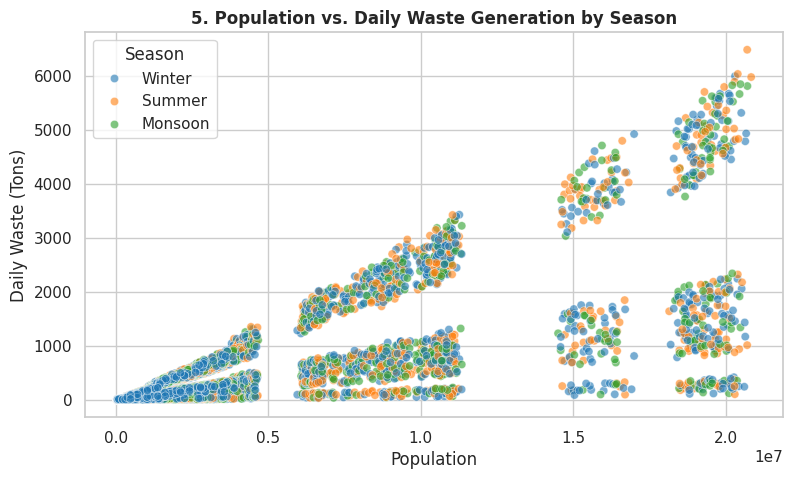

In [40]:
# 5. Population vs. Daily Waste (Hue: Season)
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='Population', y='Daily_Waste_Generation_Tons', hue='Season', alpha=0.6, palette='tab10')
plt.title('5. Population vs. Daily Waste Generation by Season', fontsize=12, fontweight='bold')
plt.xlabel('Population')
plt.ylabel('Daily Waste (Tons)')
plt.show()
#Places a dot for every single row of data. By plotting Population on the X-axis and Waste on the Y-axis, we can physically see if higher populations lead to more waste.

In [ ]:
Chart 5: Population vs. Daily Waste by Season (Scatter Plot)

What it shows: The relationship between a city's population size and its waste, color-coded by seasons.

In simple terms: Each dot represents a city. As the population goes up on the screen, does the waste go up too? The colors show if certain seasons change that pattern.

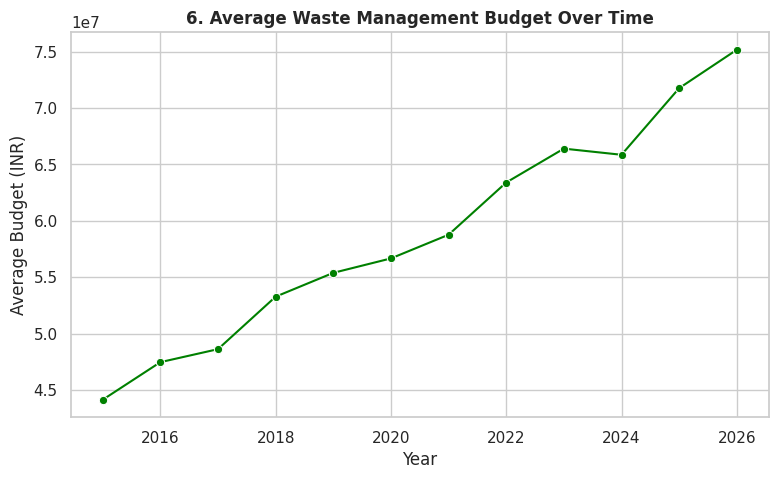

In [41]:
# 6. Waste Management Budget over the Years
plt.figure(figsize=(9, 5))
sns.lineplot(data=df, x='Year', y='Waste_Management_Budget_INR', estimator='mean', errorbar=None, marker='o', color='green')
plt.title('6. Average Waste Management Budget Over Time', fontsize=12, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Average Budget (INR)')
plt.show() #Connects data points over time. We use this to see if waste budgets are rising or falling year by year.

In [ ]:
Chart 6: Average Waste Management Budget Over Time (Line Chart)

What it shows: How money spent on waste management has changed over the years.

In simple terms: It draws a line tracking whether city budgets for trash cleanup have been increasing over time.

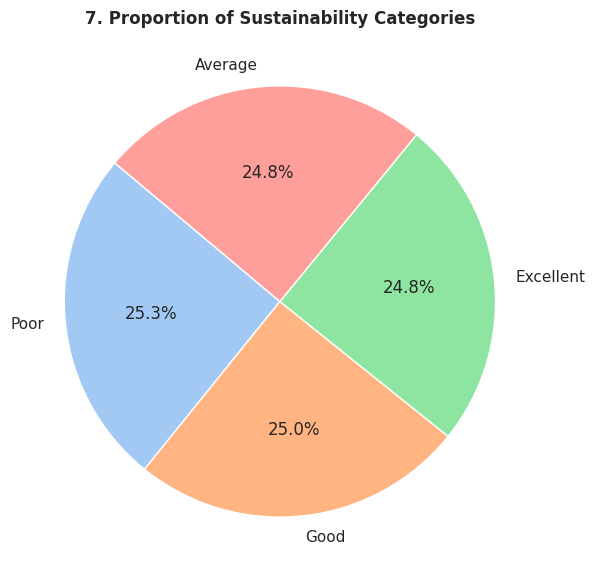

In [42]:
# 7. Proportion of Sustainability Categories
plt.figure(figsize=(7, 7))
sustainability_counts = df['Sustainability_Category'].value_counts()
plt.pie(sustainability_counts, labels=sustainability_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('7. Proportion of Sustainability Categories', fontsize=12, fontweight='bold')
plt.show() #A standard pie chart to show percentages of a whole (used for Sustainability Categories).

In [ ]:
Chart 7: Proportion of Sustainability Categories (Pie Chart)

What it shows: The percentage breakdown of cities falling into different sustainability groups (like Good, Average, Poor).

In simple terms: A classic slice-of-pie chart showing what percentage of cities are doing well environmentally versus those that are struggling.

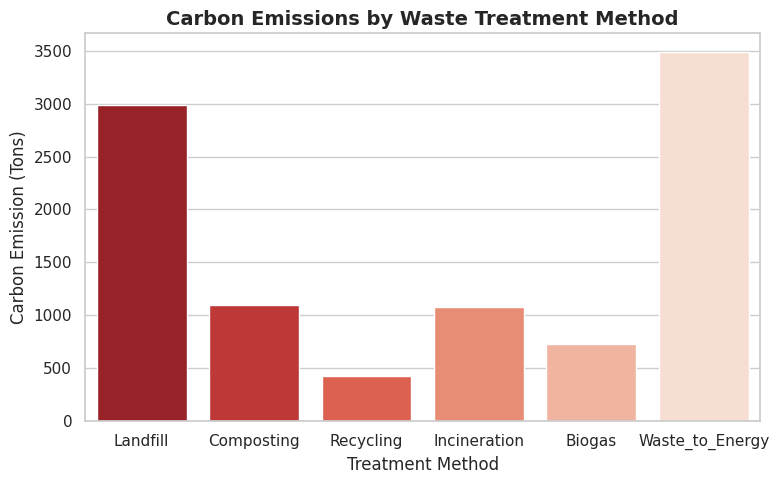

In [33]:
# 8. Carbon Emissions by Treatment Method
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Treatment_Method', y='Carbon_Emission_From_Waste', ci=None, palette='Reds_r')
plt.title('Carbon Emissions by Waste Treatment Method', fontsize=14, fontweight='bold')
plt.xlabel('Treatment Method', fontsize=12)
plt.ylabel('Carbon Emission (Tons)', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
Chart 8: Carbon Emissions by Treatment Method (Bar Plot)

What it shows: How much carbon pollution is created by different ways of getting rid of trash.

In simple terms: It compares methods like Landfilling vs. Composting to show which one is worse for the planet (spoiler: landfills create way more emissions!).

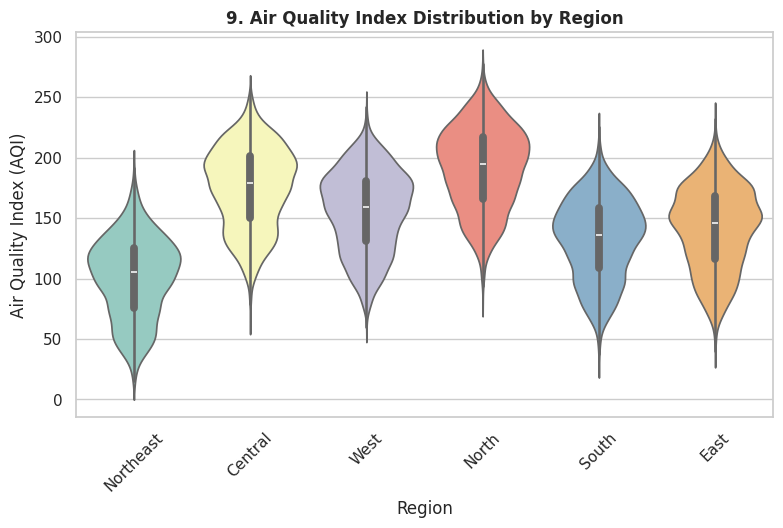

In [37]:
# 9. Air Quality Index Distribution by Region
plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x='Region', y='Air_Quality_Index', palette='Set3')
plt.title('9. Air Quality Index Distribution by Region', fontsize=12, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Air Quality Index (AQI)')
plt.xticks(rotation=45)
plt.show()
#A mix between a boxplot and a histogram. It gets wider where the data is most dense. We use it to see the distribution of Air Quality across regions.

In [ ]:
Chart 9: Air Quality Index Distribution by Region (Violin Plot)

What it shows: The spread of air pollution (AQI) across different regions of India.

In simple terms: It uses bean-shaped graphs to show which parts of the country have clean air versus parts dealing with heavy smog and pollution.

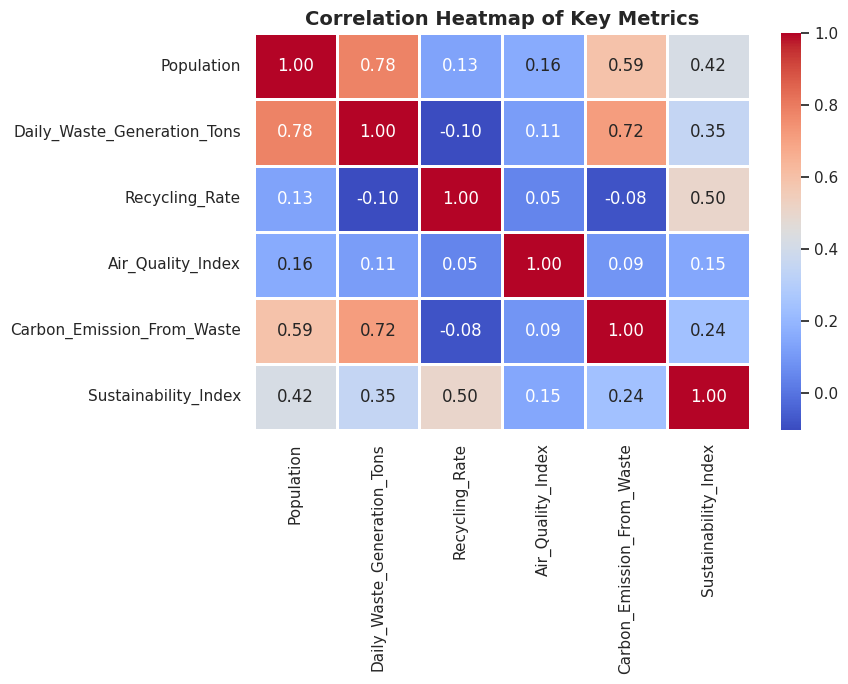

In [36]:
# 10. Correlation Heatmap of Key Metrics
plt.figure(figsize=(9, 7))
num_cols = ['Population', 'Daily_Waste_Generation_Tons', 'Recycling_Rate', 'Air_Quality_Index', 'Carbon_Emission_From_Waste', 'Sustainability_Index']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=1)
plt.title('Correlation Heatmap of Key Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
Chart 10: Correlation Heatmap of Key Metrics (Heatmap)

What it shows: How different numbers connect to and affect each other.

In simple terms: It’s a color-coded grid. Dark red or blue squares show when two things strongly influence each other (like how higher population directly links to more waste).
#This calculates the mathematical relationship (correlation) between all our number columns.
#1.00 means a perfect positive link (as one goes up, the other goes up)
#-1.00 means a perfect negative link (as one goes up, the other goes down).
#The colors make it easy to spot these links instantly.

In [43]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

**Introduction**

**What you say**:
"Hi everyone, and welcome! Today, I’m excited to walk you through my final data analytics project.
To give you a quick background: as India grows rapidly through urbanization, managing municipal waste efficiently has become one of our biggest environmental challenges. For this project, I took a large dataset tracking waste generation, treatment methods, and sustainability metrics across Indian cities. My goal was to use Python to dive deep into the data, uncover hidden trends, and figure out what our current waste management practices are actually doing to our environment."

**The 4 Simple Steps We Follow**
"To keep things neat and easy to follow, I broke the project down into four straightforward steps:

First, loading the data into Google Colab.

Second, cleaning the data—getting rid of blank rows, removing duplicates, and doing a bit of math to add new columns.

Third, building the charts—creating 10 separate, clean visualizations using Python.

And last, pulling out the key insights and explaining what the numbers actually mean

**Step 1 – Loading the Data**

"For Step 1, the code is pretty short. We used files.upload() to pop open a window so we could upload our CSV file straight into Google Colab. Then, pd.read_csv() reads that file and stores it in a table called a DataFrame—which is basically just like opening an Excel spreadsheet right inside Python."

**Step 2 – Cleaning the Data & Adding Math**

"Next up, we cleaned everything up. We used dropna() to drop any rows with missing info so it wouldn't mess up our math, and drop_duplicates() to make sure we didn't count anything twice.
I also wanted to add a bit of extra value, so I created a brand new column called Annual_Waste_Generation_Tons by taking the daily waste and multiplying it by 365 to get the yearly totals."

**Step 3 – Making the Clean Chart**s

"When it came to the charts, I wanted them to look super clean and readable. Instead of stuffing everything into one messy grid, I wrote the code to generate 10 individual, standalone charts. That way, every title and label is large, crystal clear, and easy for everyone to see."

**The Pros (Merits) of Our Approach**

"Why did I choose this approach?
Well, it's very beginner-friendly because it relies on popular Python tools like pandas and seaborn. Breaking the charts into individual windows also means no squinting—everything is crisp and easy to talk about. Plus, creating custom math columns shows you actually dug into the numbers instead of just using the raw file."

**The Cons (Demerits) & What to Watch Out For**

"Of course, every project has a few limitations to keep in mind.
For one, using dropna() deletes an entire row if even an unimportant cell is blank, which can accidentally throw away good data. Also, multiplying daily waste by 365 assumes waste generation is the exact same every single day, whereas in real life, holidays and festivals cause massive spikes."

**What Did We Discover? (Key Insights)**

"To wrap things up, what did the data actually tell us?
First, big cities make big waste: Metro areas generate vastly more trash than smaller towns due to population density.
Second, landfills are worse for carbon emissions compared to recycling or composting.
And third, there's a clear link showing that areas with heavier air pollution tend to have lower overall sustainability scores.

Thank you so much! I'd be happy to answer any questions you might have."